# **Overview**
This notebook builds an end‑to‑end pipeline that:

* loads the four CSV files (candidates, companies, listings, requirements) from their GitHub raw URLs;

* normalises and validates material streams / types;

* derives all necessary features (product compatibility, distance category, quantity comparison) from cleaned inputs;

* trains a scikit‑learn pipeline (logistic regression) with group‑aware splitting to test generalisation across companies;

* evaluates the model (class balance, confusion matrix, precision/recall/F1, ROC‑AUC);

* provides an interactive prompt for predicting a single trade;

* exports the fitted pipeline, metrics, normalisation mappings and feature schema for download;

* explains how to reuse the same pipeline for future labelled trade outcomes.

# **Import & Setup**

In [44]:
# Standard library
import io, json, os, re, sys, warnings
from datetime import datetime

# Third‑party
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import (GroupShuffleSplit, StratifiedGroupKFold,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, StandardScaler, OrdinalEncoder)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

In [45]:
# ------------------------------------------------------------------
# GitHub raw URLs for the dataset
# ------------------------------------------------------------------
CANDIDATES_URL = "https://raw.githubusercontent.com/riddhimacodes17/ReSource/refs/heads/main/dataset/candidates.csv"
COMPANIES_URL   = "https://raw.githubusercontent.com/riddhimacodes17/ReSource/refs/heads/main/dataset/companies.csv"
LISTINGS_URL    = "https://raw.githubusercontent.com/riddhimacodes17/ReSource/refs/heads/main/dataset/listings.csv"
REQUIREMENTS_URL= "https://raw.githubusercontent.com/riddhimacodes17/ReSource/refs/heads/main/dataset/requirements.csv"

# **Load the Dataset**

In [46]:
def load_csv(url: str) -> pd.DataFrame:
    """Load a CSV directly from a raw GitHub URL."""
    resp = requests.get(url)
    resp.raise_for_status()
    return pd.read_csv(io.StringIO(resp.text))

df_candidates = load_csv(CANDIDATES_URL)
df_companies  = load_csv(COMPANIES_URL)
df_listings   = load_csv(LISTINGS_URL)
df_requirements = load_csv(REQUIREMENTS_URL)

print("candidates :", df_candidates.shape)
print("companies  :", df_companies.shape)
print("listings   :", df_listings.shape)
print("requirements:", df_requirements.shape)

candidates : (7200, 15)
companies  : (100, 5)
listings   : (7200, 6)
requirements: (7200, 6)


In [47]:
# Quick look at the candidates schema (the labelled dataset)
display(df_candidates.head(3))
display(df_candidates.dtypes)

,candidate_id,buyer_company_id,seller_company_id,buyer_material_stream,buyer_material_type,seller_material_stream,seller_material_type,required_quantity,available_quantity,quantity_unit,distance_km,accepted,distance_category,product_compatibility,quantity_comparison
0,M00001,C091,C037,Water,Process water,Water,Process water,28804.57,39048.17,L,1.941,1,<=2km,same_name_same_type,req_lt_avail
1,M00002,C074,C027,Steel,Mixed steel scrap,Steel,Mixed steel scrap,3225.74,9169.95,kg,1.815,1,<=2km,same_name_same_type,req_lt_avail
2,M00003,C081,C058,Steel,Carbon steel scrap,Steel,Carbon steel scrap,7555.68,14417.31,kg,1.541,1,<=2km,same_name_same_type,req_lt_avail


,0
candidate_id,object
buyer_company_id,object
seller_company_id,object
buyer_material_stream,object
buyer_material_type,object
seller_material_stream,object
seller_material_type,object
required_quantity,float64
available_quantity,float64
quantity_unit,object


In [48]:
# Check class balance of the target
print(df_candidates["accepted"].value_counts(dropna=False))
print(f"Acceptance rate: {df_candidates['accepted'].mean():.3f}")

accepted
0    4626
1    2574
Name: count, dtype: int64
Acceptance rate: 0.357


# **Data Inspection and Cleaning**

In [49]:
# ------------------------------------------------------------------
# Merge company information for buyer and seller
# ------------------------------------------------------------------
# We keep only the columns that are useful for generalisation:
# primary_stream and region of each company.
comp_buyer = df_companies[["company_id", "primary_stream", "region"]].rename(
    columns={"company_id": "buyer_company_id",
             "primary_stream": "buyer_primary_stream",
             "region": "buyer_region"})
comp_seller = df_companies[["company_id", "primary_stream", "region"]].rename(
    columns={"company_id": "seller_company_id",
             "primary_stream": "seller_primary_stream",
             "region": "seller_region"})

df = df_candidates.merge(comp_buyer, on="buyer_company_id", how="left")
df = df.merge(comp_seller, on="seller_company_id", how="left")
print(df.shape)
display(df.head(3))

(7200, 19)


,candidate_id,buyer_company_id,seller_company_id,buyer_material_stream,buyer_material_type,seller_material_stream,seller_material_type,required_quantity,available_quantity,quantity_unit,distance_km,accepted,distance_category,product_compatibility,quantity_comparison,buyer_primary_stream,buyer_region,seller_primary_stream,seller_region
0,M00001,C091,C037,Water,Process water,Water,Process water,28804.57,39048.17,L,1.941,1,<=2km,same_name_same_type,req_lt_avail,Glass,Synthetic Region 1,Paper,Synthetic Region 1
1,M00002,C074,C027,Steel,Mixed steel scrap,Steel,Mixed steel scrap,3225.74,9169.95,kg,1.815,1,<=2km,same_name_same_type,req_lt_avail,Steel,Synthetic Region 2,Plastic,Synthetic Region 3
2,M00003,C081,C058,Steel,Carbon steel scrap,Steel,Carbon steel scrap,7555.68,14417.31,kg,1.541,1,<=2km,same_name_same_type,req_lt_avail,Glass,Synthetic Region 4,Paper,Synthetic Region 3


In [50]:
# ------------------------------------------------------------------
# Check for missing values in the columns we will use
# ------------------------------------------------------------------
cols_of_interest = [
    "buyer_material_stream", "buyer_material_type",
    "seller_material_stream", "seller_material_type",
    "required_quantity", "available_quantity", "quantity_unit",
    "distance_km", "accepted",
    "buyer_primary_stream", "seller_primary_stream",
    "buyer_region", "seller_region"
]
print(df[cols_of_interest].isnull().sum())

buyer_material_stream     0
buyer_material_type       0
seller_material_stream    0
seller_material_type      0
required_quantity         0
available_quantity        0
quantity_unit             0
distance_km               0
accepted                  0
buyer_primary_stream      0
seller_primary_stream     0
buyer_region              0
seller_region             0
dtype: int64


# **Normalisation and Validation**

In [51]:
# ------------------------------------------------------------------
# Allowed top‑level streams and their material types
# ------------------------------------------------------------------
ALLOWED_STREAMS = ["Steel", "Plastic", "Paper", "Water", "Glass"]

ALLOWED_TYPES = {
    "Steel":   ["Mixed steel scrap", "Carbon steel scrap",
                "Stainless steel scrap", "Steel sheets and plates"],
    "Plastic": ["Mixed plastics", "PET", "HDPE", "LDPE", "PP", "PVC", "PS"],
    "Paper":   ["Mixed paper", "Corrugated cardboard"],
    "Water":   ["Water", "Process water", "Cooling water", "Treated water"],
    "Glass":   ["Mixed glass", "Coloured glass"],
}

# ------------------------------------------------------------------
# Helper: normalise a string (lower‑case, strip, collapse spaces)
# ------------------------------------------------------------------
def _clean(s: str) -> str:
    if pd.isna(s):
        return ""
    return re.sub(r"\s+", " ", str(s).strip().lower())

# ------------------------------------------------------------------
# Normalise a material stream
# ------------------------------------------------------------------
def normalize_stream(stream: str) -> str:
    """Return the canonical stream name or a fallback if unrecognised."""
    cleaned = _clean(stream)
    # Direct match after cleaning
    for canonical in ALLOWED_STREAMS:
        if _clean(canonical) == cleaned:
            return canonical
    # Common synonyms / variations
    synonyms = {
        "steel": "Steel",
        "plastic": "Plastic",
        "plastics": "Plastic",
        "paper": "Paper",
        "cardboard": "Paper",
        "water": "Water",
        "glass": "Glass",
    }
    for key, value in synonyms.items():
        if key in cleaned:
            return value
    # Fallback – first stream (Steel)
    print(f"⚠️  Stream '{stream}' not recognised")
    return none

# ------------------------------------------------------------------
# Normalise a material type within a given stream
# ------------------------------------------------------------------
def normalize_type(stream: str, material_type: str) -> str:
    """
    Map material_type to the canonical type for the given stream.
    If no match, fall back to the first type listed for that stream.
    """
    stream = normalize_stream(stream)
    cleaned = _clean(material_type)
    allowed = ALLOWED_TYPES[stream]
    # Exact match after cleaning
    for t in allowed:
        if _clean(t) == cleaned:
            return t
    # Partial match (e.g. "stainless" matches "Stainless steel scrap")
    for t in allowed:
        if cleaned in _clean(t) or _clean(t) in cleaned:
            return t
    # Fallback
    fallback = allowed[0]
    print(f"⚠️  Type '{material_type}' not found for stream '{stream}'. "
          f"Falling back to '{fallback}'.")
    return fallback

In [52]:
# Test the normalisation functions
for s in ["steel", "  PLASTIC  ", "Paper", "water", "Glass"]:
    print(s, "->", normalize_stream(s))

for st, mt in [("Steel", "stainless"), ("Plastic", "pet"),
               ("Paper", "corrugated"), ("Water", "cooling"),
               ("Glass", "coloured")]:
    print(f"{st} / {mt} -> {normalize_type(st, mt)}")

steel -> Steel
  PLASTIC   -> Plastic
Paper -> Paper
water -> Water
Glass -> Glass
Steel / stainless -> Stainless steel scrap
Plastic / pet -> PET
Paper / corrugated -> Corrugated cardboard
Water / cooling -> Cooling water
Glass / coloured -> Coloured glass


# **Feature Engineering**
All derived features are computed from the cleaned raw inputs – never from the pre‑existing distance_category, product_compatibility or quantity_comparison columns (those are dropped to avoid leakage).

In [53]:
# ------------------------------------------------------------------
# Derive product compatibility from cleaned stream / type
# ------------------------------------------------------------------
def product_compatibility(buyer_stream, buyer_type,
                          seller_stream, seller_type) -> str:
    if (buyer_stream == seller_stream) and (buyer_type == seller_type):
        return "same_name_same_type"
    if (buyer_stream == seller_stream) and (buyer_type != seller_type):
        return "same_name_diff_type"
    return "completely_different"

# ------------------------------------------------------------------
# Derive distance category from distance_km
# ------------------------------------------------------------------
def distance_category(dist_km: float) -> str:
    if pd.isna(dist_km):
        return "unknown"
    if dist_km <= 2:
        return "<=2km"
    if dist_km <= 5:
        return "2-5km"
    if dist_km <= 7:
        return "5-7km"
    return ">7km"

# ------------------------------------------------------------------
# Derive quantity comparison
# ------------------------------------------------------------------
def quantity_comparison(req, avail) -> str:
    if pd.isna(req) or pd.isna(avail):
        return "unknown"
    if req < avail:
        return "req_lt_avail"
    if req > avail:
        return "req_gt_avail"
    return "req_eq_avail"

In [54]:
# Apply to the training dataframe
df["buyer_stream_clean"]  = df["buyer_material_stream"].apply(normalize_stream)
df["buyer_type_clean"]    = df.apply(
    lambda r: normalize_type(r["buyer_stream_clean"], r["buyer_material_type"]),
    axis=1)
df["seller_stream_clean"] = df["seller_material_stream"].apply(normalize_stream)
df["seller_type_clean"]   = df.apply(
    lambda r: normalize_type(r["seller_stream_clean"], r["seller_material_type"]),
    axis=1)

df["product_compat"] = df.apply(
    lambda r: product_compatibility(r["buyer_stream_clean"], r["buyer_type_clean"],
                                    r["seller_stream_clean"], r["seller_type_clean"]),
    axis=1)

df["dist_category"] = df["distance_km"].apply(distance_category)
df["qty_compare"]   = df.apply(
    lambda r: quantity_comparison(r["required_quantity"], r["available_quantity"]),
    axis=1)

display(df[["buyer_stream_clean", "buyer_type_clean",
            "seller_stream_clean", "seller_type_clean",
            "product_compat", "dist_category", "qty_compare"]].head())

,buyer_stream_clean,buyer_type_clean,seller_stream_clean,seller_type_clean,product_compat,dist_category,qty_compare
0,Water,Process water,Water,Process water,same_name_same_type,<=2km,req_lt_avail
1,Steel,Mixed steel scrap,Steel,Mixed steel scrap,same_name_same_type,<=2km,req_lt_avail
2,Steel,Carbon steel scrap,Steel,Carbon steel scrap,same_name_same_type,<=2km,req_lt_avail
3,Steel,Stainless steel scrap,Steel,Stainless steel scrap,same_name_same_type,<=2km,req_lt_avail
4,Steel,Stainless steel scrap,Steel,Stainless steel scrap,same_name_same_type,<=2km,req_lt_avail


# **Preprocessing Pipeline**

In [55]:
# ------------------------------------------------------------------
# Define which columns are numeric and which are categorical
# ------------------------------------------------------------------
numeric_features = ["required_quantity", "available_quantity", "distance_km"]
categorical_features = [
    "buyer_stream_clean", "buyer_type_clean",
    "seller_stream_clean", "seller_type_clean",
    "buyer_primary_stream", "seller_primary_stream",
    "buyer_region", "seller_region",
    "product_compat", "dist_category", "qty_compare"
]

# ------------------------------------------------------------------
# Build the ColumnTransformer
# ------------------------------------------------------------------
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])

# ------------------------------------------------------------------
# Full pipeline with a simple baseline classifier
# ------------------------------------------------------------------
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

# **Group‑Aware Train / Test Split**
We use GroupShuffleSplit on buyer_company_id so that companies in the test set are never seen during training. This tests generalisation across companies rather than memorising repeated listings.

In [56]:
# ------------------------------------------------------------------
# Prepare X and y
# ------------------------------------------------------------------
feature_cols = numeric_features + categorical_features
X = df[feature_cols]
y = df["accepted"]
groups = df["buyer_company_id"]          # group by buyer company

# ------------------------------------------------------------------
# Split (80 % train, 20 % test)
# ------------------------------------------------------------------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")
print(f"Train acceptance rate: {y_train.mean():.3f}")
print(f"Test  acceptance rate: {y_test.mean():.3f}")

Train size: 5736, Test size: 1464
Train acceptance rate: 0.356
Test  acceptance rate: 0.363


# **Train the model**

In [57]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['required_quantity',
                                                   'available_quantity',
                                                   'distance_km']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['buyer_stream_clean',
                                                   'buyer_type_clean',
                                                   'seller_stream_clean',
                                                   'seller_type_clean',
                                                   'buyer_primary_stream',
                                                   'seller_primary_stream',
                                                   'buyer_region',
                                                   'seller_region',
                                                   'product_compat',
                                                   'dist_category',
                                                   'qty_compare'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [58]:
# Quick sanity check on the training set
train_acc = pipeline.score(X_train, y_train)
print(f"Training accuracy: {train_acc:.4f}")

Training accuracy: 0.7045


# **Evaluation Report**

Class balance (test set):
accepted
0    0.636612
1    0.363388
Name: proportion, dtype: float64


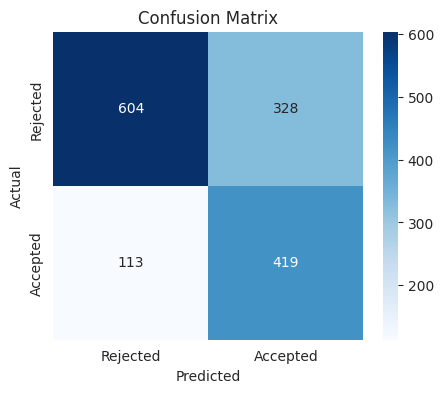

              precision    recall  f1-score   support

    Rejected       0.84      0.65      0.73       932
    Accepted       0.56      0.79      0.66       532

    accuracy                           0.70      1464
   macro avg       0.70      0.72      0.69      1464
weighted avg       0.74      0.70      0.70      1464

ROC‑AUC: 0.7849


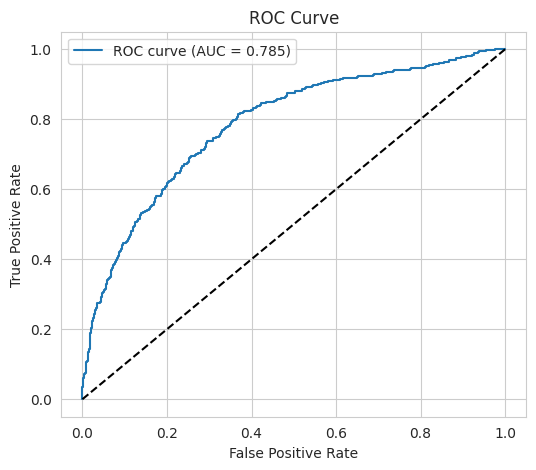

In [59]:
# ------------------------------------------------------------------
# Predictions
# ------------------------------------------------------------------
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

# ------------------------------------------------------------------
# Class balance
# ------------------------------------------------------------------
print("Class balance (test set):")
print(pd.Series(y_test).value_counts(normalize=True))

# ------------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rejected", "Accepted"],
            yticklabels=["Rejected", "Accepted"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# ------------------------------------------------------------------
# Precision, recall, F1
# ------------------------------------------------------------------
print(classification_report(y_test, y_pred, target_names=["Rejected", "Accepted"]))

# ------------------------------------------------------------------
# ROC‑AUC
# ------------------------------------------------------------------
auc = roc_auc_score(y_test, y_prob)
print(f"ROC‑AUC: {auc:.4f}")

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [60]:
# ------------------------------------------------------------------
# Observed acceptance rate per (buyer_stream, seller_stream)
# ------------------------------------------------------------------
scenario_stats = (
    df.groupby(["buyer_stream_clean", "seller_stream_clean"])["accepted"]
      .agg(["mean", "count"])
      .reset_index()
      .rename(columns={"mean": "observed_acceptance_rate",
                       "count": "n_samples"})
)
display(scenario_stats.sort_values("observed_acceptance_rate", ascending=False))

# Optionally: compare model predictions on the test set for each scenario
test_df = X_test.copy()
test_df["y_true"] = y_test.values
test_df["y_pred"] = y_pred
test_df["y_prob"] = y_prob

scenario_pred = (
    test_df.groupby(["buyer_stream_clean", "seller_stream_clean"])
           .agg(observed=("y_true", "mean"),
                predicted=("y_prob", "mean"),
                n=("y_true", "size"))
           .reset_index()
)
display(scenario_pred)

,buyer_stream_clean,seller_stream_clean,observed_acceptance_rate,n_samples
5,Paper,Paper,0.495308,959
15,Steel,Steel,0.491024,947
16,Water,Water,0.489960,996
0,Glass,Glass,0.470779,924
10,Plastic,Plastic,0.465092,974
9,Plastic,Paper,0.125000,176
7,Paper,Steel,0.124444,225
8,Plastic,Glass,0.123223,211
6,Paper,Plastic,0.118943,227
3,Glass,Steel,0.112299,187


,buyer_stream_clean,seller_stream_clean,observed,predicted,n
0,Glass,Glass,0.439791,0.608043,191
1,Glass,Paper,0.073171,0.175634,41
2,Glass,Plastic,0.142857,0.177679,35
3,Glass,Steel,0.111111,0.194021,36
4,Paper,Glass,0.114286,0.185590,35
5,Paper,Paper,0.484211,0.640845,190
6,Paper,Plastic,0.130435,0.172009,46
7,Paper,Steel,0.111111,0.213272,45
8,Plastic,Glass,0.100000,0.184840,40
9,Plastic,Paper,0.153846,0.178277,39


# **Confidence helper + calibration diagnostics**

Brier score (test set): 0.1938
  → 0.00 = perfect,  0.25 = random;  lower is better.


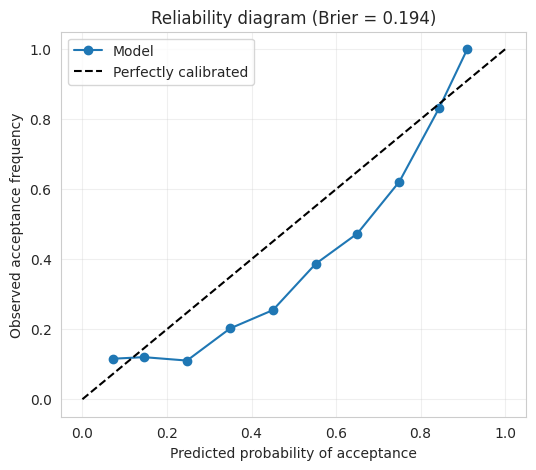

In [61]:
# ==============================================================
# CONFIDENCE SCORING + CALIBRATION DIAGNOSTICS
# --------------------------------------------------------------
# Confidence for a predicted class = probability the model
# assigns to the class it chose:
#     confidence = max(predict_proba(X))
# It is only trustworthy if the probabilities are calibrated,
# which we check with the Brier score and a reliability diagram
# (both are free and require no extra training).
# ==============================================================
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def predict_with_confidence(fitted_pipeline, X_input):
    """
    Returns (predicted_class, confidence, p_accept, p_reject, raw_logit).

    confidence = max(predict_proba)  -> model's estimated probability
                 that the predicted outcome is the correct one.
    """
    proba = fitted_pipeline.predict_proba(X_input)[0]   # [p_reject, p_accept]
    pred  = int(fitted_pipeline.predict(X_input)[0])
    confidence = float(max(proba))
    decision   = float(fitted_pipeline.decision_function(X_input)[0])
    return pred, confidence, float(proba[1]), float(proba[0]), decision

# --- Calibration diagnostics on the SAME held-out test set ---
brier = brier_score_loss(y_test, y_prob)
prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

print(f"Brier score (test set): {brier:.4f}")
print("  → 0.00 = perfect,  0.25 = random;  lower is better.")

plt.figure(figsize=(6, 5))
plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.xlabel("Predicted probability of acceptance")
plt.ylabel("Observed acceptance frequency")
plt.title(f"Reliability diagram (Brier = {brier:.3f})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [62]:
pipeline_for_confidence = pipeline

# **Interaction Prediction**

In [63]:
def interactive_predict():
    """Prompt the user for the raw inputs and return a prediction."""
    print("\n=== ReSource Trade Prediction ===")
    buyer_stream = input("Buyer material stream (e.g. Steel): ").strip()
    buyer_type   = input("Buyer material type (e.g. Mixed steel scrap): ").strip()
    seller_stream= input("Seller material stream (e.g. Steel): ").strip()
    seller_type  = input("Seller material type (e.g. Carbon steel scrap): ").strip()
    required_qty = float(input("Required quantity: "))
    available_qty= float(input("Available quantity: "))
    distance_km  = float(input("Distance (km): "))
    qty_unit     = input("Quantity unit (kg or L): ").strip() or "kg"

    # ---- Normalise ----
    b_stream = normalize_stream(buyer_stream)
    b_type   = normalize_type(b_stream, buyer_type)
    s_stream = normalize_stream(seller_stream)
    s_type   = normalize_type(s_stream, seller_type)

    # ---- Derive features ----
    prod_compat = product_compatibility(b_stream, b_type, s_stream, s_type)
    dist_cat    = distance_category(distance_km)
    qty_comp    = quantity_comparison(required_qty, available_qty)

    # ---- Build a single‑row dataframe with the same columns as training ----
    input_df = pd.DataFrame([{
        "required_quantity": required_qty,
        "available_quantity": available_qty,
        "distance_km": distance_km,
        "buyer_stream_clean": b_stream,
        "buyer_type_clean": b_type,
        "seller_stream_clean": s_stream,
        "seller_type_clean": s_type,
        "buyer_primary_stream": b_stream,      # fallback; could be improved
        "seller_primary_stream": s_stream,
        "buyer_region": "Synthetic Region 1",  # placeholder
        "seller_region": "Synthetic Region 1",
        "product_compat": prod_compat,
        "dist_category": dist_cat,
        "qty_compare": qty_comp,
    }])

    # ---- Predict + confidence ----
    pred, confidence, p_acc, p_rej, logit = predict_with_confidence(
        pipeline_for_confidence, input_df)

    label = "ACCEPTED" if pred == 1 else "REJECTED"
    print(f"\nPrediction : {label}")
    print(f"Confidence : {confidence:.2%}  "
          f"(probability assigned to the chosen class)")
    print(f"  P(accepted) = {p_acc:.2%}")
    print(f"  P(rejected) = {p_rej:.2%}")
    print(f"  Raw logit   = {logit:+.3f}")
    return pred, confidence

# Uncomment to run interactively in Colab
# interactive_predict()

# **Export Fitted Artefacts**

In [64]:
# ------------------------------------------------------------------
# Create a dictionary of artefacts to save
# ------------------------------------------------------------------
artefacts = {
    "pipeline": pipeline,
    "normalization_mappings": {
        "streams": ALLOWED_STREAMS,
        "types": ALLOWED_TYPES,
    },
    "feature_schema": {
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
    },
    "evaluation_metrics": {
        "accuracy": accuracy_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "classification_report": classification_report(
            y_test, y_pred, output_dict=True, target_names=["Rejected", "Accepted"]),
    },
    "training_info": {
        "train_size": len(X_train),
        "test_size": len(X_test),
        "random_state": RANDOM_STATE,
    },
        "confidence_method": {
        "formula": "confidence = max(predict_proba(X))",
        "description": (
            "Confidence for a prediction equals the probability the "
            "model assigns to the class it chose.  It equals "
            "P(accepted) when the prediction is ACCEPTED and "
            "P(rejected) when the prediction is REJECTED.  "
            "It is therefore the model's estimated probability that "
            "the predicted outcome is correct."
        ),
        "reliability_check": {
            "method": "Brier score + reliability diagram on held-out test set",
            "brier_score_test": float(brier),
            "n_bins_reliability": 10,
            "reliability_prob_pred": prob_pred.tolist(),
            "reliability_prob_true": prob_true.tolist(),
            "interpretation": (
                "Brier score is a strictly proper scoring rule "
                "(0 = perfect, 0.25 = random).  A reliability diagram "
                "close to the diagonal indicates well-calibrated "
                "probabilities, which is what makes the confidence "
                "score trustworthy."
            ),
        },
        "calibrated": bool('calibrated_pipeline' in globals()
                           and calibrated_pipeline is not None),
    },
}

# Save pipeline with joblib
joblib.dump(pipeline, "resource_trade_pipeline.joblib")
joblib.dump(
    {
        "pipeline": pipeline,
        "pipeline_for_confidence": pipeline_for_confidence,
        "confidence_formula": "max(predict_proba(X))",
        "brier_score_test": float(brier),
    },
    "resource_trade_pipeline.joblib",
)
# Save the rest as JSON
with open("resource_trade_artefacts.json", "w") as f:
    # Convert non‑serialisable objects to strings
    serialisable = {}
    for k, v in artefacts.items():
        if k == "pipeline":
            continue
        try:
            json.dumps(v)
            serialisable[k] = v
        except TypeError:
            serialisable[k] = str(v)
    json.dump(serialisable, f, indent=2)

print("Saved: resource_trade_pipeline.joblib, resource_trade_artefacts.json")

Saved: resource_trade_pipeline.joblib, resource_trade_artefacts.json


In [65]:
# Download the files (Colab only)
from google.colab import files
files.download("resource_trade_pipeline.joblib")
files.download("resource_trade_artefacts.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Retraining Readiness**
To reuse the pipeline with future labelled trade outcomes:

1. Load the new CSV (must contain the same raw columns as candidates.csv: buyer_material_stream, buyer_material_type, seller_material_stream, seller_material_type, required_quantity, available_quantity, quantity_unit, distance_km, accepted).

2. Merge the company metadata (primary stream, region) as done in Section 4.

3. Apply the same normalisation functions (normalize_stream, normalize_type) and feature‑engineering functions (product_compatibility, distance_category, quantity_comparison).

4. Ensure the resulting DataFrame has exactly the columns listed in numeric_features + categorical_features.

5. Call pipeline.fit(X_new, y_new) to retrain, or use pipeline.partial_fit if you prefer online learning (LogisticRegression does not support partial_fit by default; you would need to use SGDClassifier with partial_fit).

6. Re‑run the evaluation cells on a held‑out set to monitor performance.

The normalisation mappings and feature schema are saved in resource_trade_artefacts.json and can be loaded to guarantee consistency

# **Notes and Limitations**
* The dataset is synthetic; the model’s performance reflects the synthetic generation process.

* Group splitting reduces leakage but does not eliminate it completely because the same company can appear as both buyer and seller across different rows.

* The “36 scenarios” in the data correspond to unique combinations of buyer and seller material streams. Observed acceptance rates are reported, but true scenario probabilities are not available in the dataset.